## Постановка цели, описание исходных данных.

Компания «Мегалайн» — федеральный оператор сотовой связи. Клиентам предлагают два тарифных плана: «Смарт» и «Ультра». 

Цель компании-заказчика - скорректировать рекламный бюджет.

Задача аналитику - определить какой тариф приносит больше денег.
необходимо сделать предварительный анализ тарифов на небольшой выборке клиентов. 

Дано : данные 500 пользователей «Мегалайна»: кто они, откуда, каким тарифом пользуются, сколько звонков и сообщений каждый отправил за 2018 год. 


## Откройте файл с данными и изучите общую информацию

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats as st
import pylab as pl
from pandas import *

In [60]:
df_calls = pd.read_csv('/datasets/calls.csv')
df_internet = pd.read_csv('/datasets/internet.csv')
df_messages = pd.read_csv('/datasets/messages.csv')
df_tariffs = pd.read_csv('/datasets/tariffs.csv')
df_users = pd.read_csv('/datasets/users.csv')

In [61]:
display(df_calls.info())
display(df_calls.describe())
df_calls.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202607 entries, 0 to 202606
Data columns (total 4 columns):
id           202607 non-null object
call_date    202607 non-null object
duration     202607 non-null float64
user_id      202607 non-null int64
dtypes: float64(1), int64(1), object(2)
memory usage: 6.2+ MB


None

,duration,user_id
count,202607.000000,202607.000000
mean,6.755887,1253.940619
std,5.843365,144.722751
min,0.000000,1000.000000
25%,1.300000,1126.000000
50%,6.000000,1260.000000
75%,10.700000,1379.000000
max,38.000000,1499.000000


,id,call_date,duration,user_id
0,1000_0,2018-07-25,0.00,1000
1,1000_1,2018-08-17,0.00,1000
2,1000_2,2018-06-11,2.85,1000
3,1000_3,2018-09-21,13.80,1000
4,1000_4,2018-12-15,5.18,1000


In [62]:
display(df_internet.info())
display(df_internet.describe())
df_internet.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149396 entries, 0 to 149395
Data columns (total 5 columns):
Unnamed: 0      149396 non-null int64
id              149396 non-null object
mb_used         149396 non-null float64
session_date    149396 non-null object
user_id         149396 non-null int64
dtypes: float64(1), int64(2), object(2)
memory usage: 5.7+ MB


None

,Unnamed: 0,mb_used,user_id
count,149396.000000,149396.000000,149396.000000
mean,74697.500000,370.192426,1252.099842
std,43127.054745,278.300951,144.050823
min,0.000000,0.000000,1000.000000
25%,37348.750000,138.187500,1130.000000
50%,74697.500000,348.015000,1251.000000
75%,112046.250000,559.552500,1380.000000
max,149395.000000,1724.830000,1499.000000


,Unnamed: 0,id,mb_used,session_date,user_id
0,0,1000_0,112.95,2018-11-25,1000
1,1,1000_1,1052.81,2018-09-07,1000
2,2,1000_2,1197.26,2018-06-25,1000
3,3,1000_3,550.27,2018-08-22,1000
4,4,1000_4,302.56,2018-09-24,1000


In [63]:
display(df_messages.info())
display(df_messages.describe())
df_messages.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123036 entries, 0 to 123035
Data columns (total 3 columns):
id              123036 non-null object
message_date    123036 non-null object
user_id         123036 non-null int64
dtypes: int64(1), object(2)
memory usage: 2.8+ MB


None

,user_id
count,123036.000000
mean,1256.989410
std,143.523967
min,1000.000000
25%,1134.000000
50%,1271.000000
75%,1381.000000
max,1499.000000


,id,message_date,user_id
0,1000_0,2018-06-27,1000
1,1000_1,2018-10-08,1000
2,1000_2,2018-08-04,1000
3,1000_3,2018-06-16,1000
4,1000_4,2018-12-05,1000


In [64]:
df_tariffs

,messages_included,mb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,tariff_name
0,50,15360,500,550,200,3,3,smart
1,1000,30720,3000,1950,150,1,1,ultra


In [65]:
display(df_users.info())
display(df_users.describe())
df_users.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
user_id       500 non-null int64
age           500 non-null int64
churn_date    38 non-null object
city          500 non-null object
first_name    500 non-null object
last_name     500 non-null object
reg_date      500 non-null object
tariff        500 non-null object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


None

,user_id,age
count,500.000000,500.00000
mean,1249.500000,46.58800
std,144.481833,16.66763
min,1000.000000,18.00000
25%,1124.750000,32.00000
50%,1249.500000,46.00000
75%,1374.250000,62.00000
max,1499.000000,75.00000


,user_id,age,churn_date,city,first_name,last_name,reg_date,tariff
0,1000,52,NaN,Краснодар,Рафаил,Верещагин,2018-05-25,ultra
1,1001,41,NaN,Москва,Иван,Ежов,2018-11-01,smart
2,1002,59,NaN,Стерлитамак,Евгений,Абрамович,2018-06-17,smart
3,1003,23,NaN,Москва,Белла,Белякова,2018-08-17,ultra
4,1004,68,NaN,Новокузнецк,Татьяна,Авдеенко,2018-05-14,ultra


## Подготовка данных

### Приведение данных к нужным типам, исправление ошибок в данных, если они есть

ошибок нет, данные приведены к нужным типам. Можно конечно привести столбцы с датами из строчного типа в тип дата, но пока я не знаю пригодиться ли мне это. Если да, то вернусь к этому шагу.

а пока удалю ненужную мне информацию.

In [66]:
df_internet = df_internet.drop(['Unnamed: 0'], axis=1)

**в таблице df_tariffs переведём мб в Гб и переименуем соответствующий столбец**

In [67]:
df_tariffs['mb_per_month_included'] /= 1024
df_tariffs.rename(columns={'mb_per_month_included': 'gb_per_month_included'}, inplace=True)

In [68]:
df_tariffs

,messages_included,gb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,tariff_name
0,50,15.0,500,550,200,3,3,smart
1,1000,30.0,3000,1950,150,1,1,ultra


In [69]:
df_internet

,id,mb_used,session_date,user_id
0,1000_0,112.95,2018-11-25,1000
1,1000_1,1052.81,2018-09-07,1000
2,1000_2,1197.26,2018-06-25,1000
3,1000_3,550.27,2018-08-22,1000
4,1000_4,302.56,2018-09-24,1000
...,...,...,...,...
149391,1499_152,318.90,2018-10-03,1499
149392,1499_153,490.13,2018-12-14,1499
149393,1499_154,0.00,2018-10-27,1499
149394,1499_155,1246.32,2018-11-26,1499


In [70]:
df_internet.isna().mean()*100

id              0.0
mb_used         0.0
session_date    0.0
user_id         0.0
dtype: float64

In [71]:
df_users.isna().mean()*100

user_id        0.0
age            0.0
churn_date    92.4
city           0.0
first_name     0.0
last_name      0.0
reg_date       0.0
tariff         0.0
dtype: float64

тут пропуски обозначают, что у 92 % договор на предоставление услуг связи действующий

In [72]:
df_calls.isna().mean()*100

id           0.0
call_date    0.0
duration     0.0
user_id      0.0
dtype: float64

In [73]:
df_messages.isna().mean()*100

id              0.0
message_date    0.0
user_id         0.0
dtype: float64

In [74]:
df_users.duplicated().sum()

0

In [75]:
df_internet.duplicated().sum()

0

In [76]:
df_messages.duplicated().sum()

0

In [77]:
df_users.duplicated().sum()

0

Критичных пропусков в датафреймах нет, дубликатов нет.

### количество сделанных звонков и израсходованных минут разговора по месяцам по каждому пользователю 

In [78]:
df_calls.head()

,id,call_date,duration,user_id
0,1000_0,2018-07-25,0.00,1000
1,1000_1,2018-08-17,0.00,1000
2,1000_2,2018-06-11,2.85,1000
3,1000_3,2018-09-21,13.80,1000
4,1000_4,2018-12-15,5.18,1000


In [79]:
pd.DatetimeIndex(df_calls['call_date']).year.unique()

Int64Index([2018], dtype='int64', name='call_date')

так как год у нас не меняется (везде 2018), оставим вместо полной даты только номер месяца. так будет проще и удобней.

In [80]:
df_calls['month'] = pd.DatetimeIndex(df_calls['call_date']).month

согласно тарифам длительность звонков при подсчёте ежемесячной платы округляется до минут в большую сторону. Поэтому применим округление до целых вверх - np.ceil

In [ ]:
df_calls['duration'] = np.ceil(df_calls['duration'])

Для выполнения текущей задачи, сгруппирую данные по пользователям и месяцам, и применю арифметические операции count, sum , таким образом подсчитаю количество звонков и минут помесячно по каждому пользователю. применю именованную агрегацию.

In [ ]:
df_1 = df_calls.groupby(['user_id', 'month'], as_index=False).agg(
    count_calls=('duration', 'count'),
    minut_used=('duration', 'sum')
)
df_1.round(2)
df_1.head()

,user_id,month,count_calls,minut_used
0,1000,5,22,159.0
1,1000,6,43,172.0
2,1000,7,47,340.0
3,1000,8,52,408.0
4,1000,9,58,466.0


### количество отправленных сообщений по месяцам по каждому пользователю 

In [83]:
df_messages.head()

,id,message_date,user_id
0,1000_0,2018-06-27,1000
1,1000_1,2018-10-08,1000
2,1000_2,2018-08-04,1000
3,1000_3,2018-06-16,1000
4,1000_4,2018-12-05,1000


In [84]:
df_messages['month'] = pd.DatetimeIndex(df_messages['message_date']).month

In [ ]:
df_2 = df_messages.groupby(['user_id', 'month'], as_index=False).agg(
    messages_used=('id', 'count')
)
df_2.head()

,user_id,month,messages_used
0,1000,5,22
1,1000,6,60
2,1000,7,75
3,1000,8,81
4,1000,9,57


### объем израсходованного интернет-трафика по месяцам по каждому пользователю 

In [86]:
df_internet.head()

,id,mb_used,session_date,user_id
0,1000_0,112.95,2018-11-25,1000
1,1000_1,1052.81,2018-09-07,1000
2,1000_2,1197.26,2018-06-25,1000
3,1000_3,550.27,2018-08-22,1000
4,1000_4,302.56,2018-09-24,1000


In [87]:
df_internet['month'] = pd.DatetimeIndex(df_internet['session_date']).month

Для решения данной задачи , также необходимо сгруппировать по пользоателям и месяцам и подсчитать объём израсходованного трафика по месячно (применяю метод sum), далее перевожу мб в гб и округляю вверх до целых, согласно условиям тарифов компании оператора.

In [ ]:
df_3 = (
    df_internet
    .groupby(['user_id', 'month'], as_index=False)
    .agg(mb_sum=('mb_used', 'sum'))
    .assign(gb_used=lambda x: np.ceil(x['mb_sum'] / 1024))
    .drop(columns=['mb_sum'])
)
df_3.head()

,user_id,month,gb_used
0,1000,5,3.0
1,1000,6,23.0
2,1000,7,14.0
3,1000,8,14.0
4,1000,9,15.0


### помесячная выручка с каждого пользователя

для подсчёта помесячной выручки будет удобно склеить таблицы df_1, df_2, df_3, полученные на предыдущем шаге, а также прикрепить к ним таблицу df_users, для определения таифа пользователя.
Для начала посмотрим на размеры таблиц, сколько пользователей по каждому виду трафика.

In [89]:
len(df_1['user_id'].unique())

492

In [90]:
len(df_2['user_id'].unique())

426

In [91]:
len(df_3['user_id'].unique())

497

видим что размеры не равны, и чтобы не потерять данные воспользуюсь типом объединения - outer join. Склеиваю 1,2,3 датафрейм.

In [92]:
df = df_3.merge(df_2, how='outer')

In [93]:
df = df.merge(df_1, how='outer')

In [94]:
df

,user_id,month,gb_used,messages_used,count_calls,minut_used
0,1000,5,3.0,22.0,22.0,159.0
1,1000,6,23.0,60.0,43.0,172.0
2,1000,7,14.0,75.0,47.0,340.0
3,1000,8,14.0,81.0,52.0,408.0
4,1000,9,15.0,57.0,58.0,466.0
...,...,...,...,...,...,...
3209,1273,11,NaN,29.0,45.0,272.0
3210,1273,12,NaN,39.0,41.0,260.0
3211,1377,2,NaN,2.0,23.0,179.0
3212,1392,2,NaN,3.0,2.0,13.0


Тариф «Смарт»

Ежемесячная плата: 550 рублей
Включено 500 минут разговора, 50 сообщений и 15 Гб интернет-трафика
Стоимость услуг сверх тарифного пакета: 1. минута разговора: 3 рубля («Мегалайн» всегда округляет вверх значения минут и мегабайтов. Если пользователь проговорил всего 1 секунду, в тарифе засчитывается целая минута); 2. сообщение: 3 рубля; 3. 1 Гб интернет-трафика: 200 рублей.

Тариф «Ультра»

Ежемесячная плата: 1950 рублей
Включено 3000 минут разговора, 1000 сообщений и 30 Гб интернет-трафика
Стоимость услуг сверх тарифного пакета: 1. минута разговора: 1 рубль; 2. сообщение: 1 рубль; 3. 1 Гб интернет-трафика: 150 рублей.


Примечание:
«Мегалайн» всегда округляет секунды до минут, а мегабайты — до гигабайт. Каждый звонок округляется отдельно: даже если он длился всего 1 секунду, будет засчитан как 1 минута.
Для веб-трафика отдельные сессии не считаются. Вместо этого общая сумма за месяц округляется в бо́льшую сторону. Если абонент использует 1025 мегабайт в этом месяце, с него возьмут плату за 2 гигабайта.

Вспоминаю , что есть ещё датафрейм с данными по пользователям и там есть информация о названии тарифа. Приклеиваю его также к общей таблице способом объединения 'left', так как нам нужна информация только о тех пользователях о которых у нас есть данные по звонкам и\или расходу интернет-трафика и\или сообщений.

In [95]:
df_users.head()

,user_id,age,churn_date,city,first_name,last_name,reg_date,tariff
0,1000,52,NaN,Краснодар,Рафаил,Верещагин,2018-05-25,ultra
1,1001,41,NaN,Москва,Иван,Ежов,2018-11-01,smart
2,1002,59,NaN,Стерлитамак,Евгений,Абрамович,2018-06-17,smart
3,1003,23,NaN,Москва,Белла,Белякова,2018-08-17,ultra
4,1004,68,NaN,Новокузнецк,Татьяна,Авдеенко,2018-05-14,ultra


In [96]:
df = df.merge(df_users[['user_id','city','tariff']], how='left')
df

,user_id,month,gb_used,messages_used,count_calls,minut_used,city,tariff
0,1000,5,3.0,22.0,22.0,159.0,Краснодар,ultra
1,1000,6,23.0,60.0,43.0,172.0,Краснодар,ultra
2,1000,7,14.0,75.0,47.0,340.0,Краснодар,ultra
3,1000,8,14.0,81.0,52.0,408.0,Краснодар,ultra
4,1000,9,15.0,57.0,58.0,466.0,Краснодар,ultra
...,...,...,...,...,...,...,...,...
3209,1273,11,NaN,29.0,45.0,272.0,Курган,ultra
3210,1273,12,NaN,39.0,41.0,260.0,Курган,ultra
3211,1377,2,NaN,2.0,23.0,179.0,Брянск,ultra
3212,1392,2,NaN,3.0,2.0,13.0,Челябинск,ultra


в процессе склеивания таблиц образовались пропуски, так как длина датафреймов на входе была разная, то есть какие то пользователи наример пользовались интернетом, но не пользовались голосовой связью и наоборот.
следовательно на месте пропусков должны быть нули, что будет означать , что абонент не пользовался тем или иным видом трафика.
Заменю пропуски нулями.

In [97]:
df['messages_used'] = df['messages_used'].fillna(0)
df['gb_used'] = df['gb_used'].fillna(0)
df['minut_used'] = df['minut_used'].fillna(0)

вот теперь в таблице есть все необходимые данные для того , чтобы посчитать помесячно выручку с каждого пользователя.
данные по абонентской плате и цены на трафик сверхлимита, возьму из таблицы тарифы.

In [ ]:
df = df.merge(df_tariffs, left_on='tariff', right_on='tariff_name', how='left')

df['total_price'] = (
    df['rub_monthly_fee']
    + np.maximum(0, merged['messages_used'] - merged['messages_included']) * merged['rub_per_message']
    + np.maximum(0, merged['gb_used'] - merged['gb_per_month_included']) * merged['rub_per_gb']
    + np.maximum(0, merged['minutes_used'] - merged['minutes_included']) * merged['rub_per_minute']
)

df = df.drop(columns=['tariff_name', 'rub_monthly_fee',
    'messages_included', 'minutes_included', 'gb_per_month_included',
    'rub_per_message', 'rub_per_minute', 'rub_per_gb'])

In [44]:
df.head(5)

,user_id,month,gb_used,messages_used,count_calls,minut_used,city,tariff,total_price
0,1000,5,3.0,22.0,22.0,159.0,Краснодар,ultra,1950.0
1,1000,6,23.0,60.0,43.0,172.0,Краснодар,ultra,1950.0
2,1000,7,14.0,75.0,47.0,340.0,Краснодар,ultra,1950.0
3,1000,8,14.0,81.0,52.0,408.0,Краснодар,ultra,1950.0
4,1000,9,15.0,57.0,58.0,466.0,Краснодар,ultra,1950.0


в столбце total_price получаю выручку по каждому пользователю помесячно.

## Анализ данных

Сколько минут разговора, сколько сообщений и какой объём интернет-трафика требуется пользователям каждого тарифа в месяц? Посчитайте среднее количество, дисперсию и стандартное отклонение. Постройте гистограммы. Опишите распределения.

Проверю нет ли таких кто не пользовался бы никакими услугами связи.

In [45]:
len(df.query('(gb_used == 0) & (messages_used == 0) & (minut_used == 0) '))

0

таких не оказалось

Подсчитаю среднее, медиану, дисперсию, стандартное отклонение сгруппировав данные по тарифам и по месяцам. Округлю показатели до целых значений, уберу мультииндекс с таблицы, переименую столбцы.

In [ ]:
df_gr_month = (
    df.groupby(['tariff', 'month'], as_index=False)
      .agg(
          count_users=('gb_used', 'count'),
          gb_used_median=('gb_used', 'median'),
          gb_used_mean=('gb_used', 'mean'),
          gb_used_var=('gb_used', np.var),
          gb_used_std=('gb_used', np.std),
          messages_used_median=('messages_used', 'median'),
          messages_used_mean=('messages_used', 'mean'),
          messages_used_var=('messages_used', np.var),
          messages_used_std=('messages_used', np.std),
          minutes_used_median=('minutes_used', 'median'),
          minutes_used_mean=('minutes_used', 'mean'),
          minutes_used_var=('minutes_used', np.var),
          minutes_used_std=('minutes_used', np.std),
      )
)
df_gr_month.round(2)

,tariff,month,count_users,gb_used_median,gb_used_mean,gb_used_var,gb_used_std,messages_used_median,messages_used_mean,messages_used_var,messages_used_std,minut_used_median,minut_used_mean,minut_used_var,minut_used_std
0,smart,1,34.0,7.0,9.0,40.0,7.0,15.0,19.0,263.0,17.0,163.0,204.0,23788.0,155.0
1,smart,2,58.0,13.0,12.0,38.0,7.0,20.0,25.0,474.0,22.0,258.0,299.0,36413.0,191.0
2,smart,3,77.0,16.0,16.0,33.0,6.0,23.0,32.0,719.0,27.0,409.0,391.0,36824.0,192.0
3,smart,4,112.0,14.0,14.0,32.0,6.0,28.0,31.0,603.0,25.0,369.0,368.0,34779.0,187.0
4,smart,5,141.0,16.0,16.0,35.0,6.0,30.0,34.0,731.0,28.0,433.0,388.0,34821.0,187.0
5,smart,6,164.0,16.0,16.0,32.0,6.0,28.0,34.0,807.0,29.0,400.0,396.0,30743.0,176.0
6,smart,7,201.0,16.0,16.0,34.0,6.0,29.0,34.0,800.0,29.0,414.0,409.0,32251.0,180.0
7,smart,8,235.0,17.0,17.0,31.0,6.0,27.0,34.0,839.0,29.0,432.0,422.0,34794.0,187.0
8,smart,9,260.0,16.0,17.0,26.0,6.0,30.0,34.0,791.0,29.0,435.0,429.0,33536.0,184.0
9,smart,10,294.0,17.0,17.0,33.0,6.0,30.0,34.0,817.0,29.0,428.0,427.0,35393.0,189.0


In [47]:
df_gr_month_ultra = df_gr_month.query('tariff == ("ultra")')
df_gr_month_smart = df_gr_month.query('tariff == ("smart")')

<div class="alert alert-info">
<b>посчитаю необходимые статистики ниже - </b>
<br>
</div>

In [48]:
df_gr_tariff = df.groupby(['tariff']).agg({
            'gb_used': ['count', 'median', 'mean', np.var, np.std], 
            'messages_used': ['median', 'mean', np.var, np.std], 
            'minut_used': ['median', 'mean', np.var, np.std]
            }).apply(np.ceil).reset_index()

df_gr_tariff.columns = ['_'.join(col).rstrip('_') for col in df_gr_tariff.columns.values]
df_gr_tariff.rename(columns = {'gb_used_count' : 'count_users'}, inplace = True)
df_gr_tariff.round(2)

,tariff,count_users,gb_used_median,gb_used_mean,gb_used_var,gb_used_std,messages_used_median,messages_used_mean,messages_used_var,messages_used_std,minut_used_median,minut_used_mean,minut_used_var,minut_used_std
0,smart,2229.0,17.0,17.0,34.0,6.0,28.0,34.0,797.0,29.0,422.0,418.0,36220.0,191.0
1,ultra,985.0,19.0,20.0,98.0,10.0,38.0,50.0,2286.0,48.0,518.0,527.0,100874.0,318.0


In [123]:
# КОД РЕВЬЮЕРА

df.pivot_table(index='tariff', values=['minut_used', 'messages_used', 'gb_used'],
                       aggfunc=['median', 'mean', 'std', 'var'])

median                                mean                            \
       gb_used messages_used minut_used    gb_used messages_used  minut_used   
tariff                                                                         
smart     17.0          28.0      422.0  16.328847     33.384029  417.934948   
ultra     19.0          38.0      518.0  19.494416     49.363452  526.623350   

             std                                  var                \
         gb_used messages_used  minut_used    gb_used messages_used   
tariff                                                                
smart   5.747061     28.227876  190.313730  33.028705    796.812958   
ultra   9.853511     47.804457  317.606098  97.091686   2285.266143   

                       
           minut_used  
tariff                 
smart    36219.315784  
ultra   100873.633397

**посмотрим количество пользователей по месяцам по разным тарифам (размеры выборки по месяцам)**

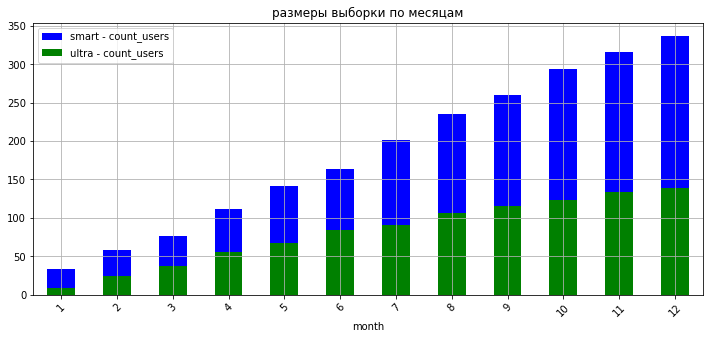

In [82]:
ax = df_gr_month_smart.plot.bar(x='month', y = 'count_users', color = 'Blue', label='smart - count_users', figsize=(12, 5),title='размеры выборки по месяцам')
df_gr_month_ultra.plot.bar(x='month', y = 'count_users', color = 'Green', label='ultra - count_users',rot=45, grid = True, ax=ax);

<div class="alert alert-success" style="border-radius: 15px; box-shadow: 4px 4px 4px; border: 1px solid ">
<b> Комментарий ревьюера</b>
    
Все верно. Но не забывай про заголовки :) 
</div>

<div class="alert alert-info">
<b>подписал</b>
<br>
</div>

- из графика видно, что с каждым месяцем количество абонентов пропорционально возрастает, причём количество пользователей тарифа смарт растет быстрее. пользователей смарт-тарифа больше чем в 2 раза превышает количество абонентов ультра почти в каждом месяце.

**построим бар-графики по среднемесячным потреблениям разных типов трафика в зависимост от тарифа.**

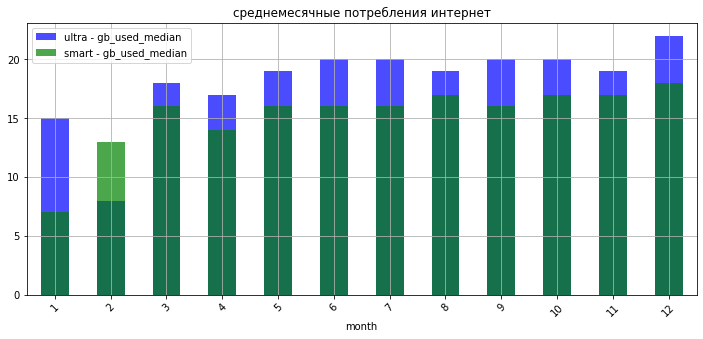

In [85]:
ax = df_gr_month_ultra.plot.bar(x='month', y = 'gb_used_median', color = 'Blue', label='ultra - gb_used_median', alpha=0.7,figsize=(12, 5), title='среднемесячные потребления интернет')
df_gr_month_smart.plot.bar(x='month', y = 'gb_used_median', color = 'Green', label='smart - gb_used_median',rot=45,alpha=0.7, grid = True, ax=ax);

- В тарифе ультра в среднем каждый абонент тратит 19 Гб интернет-трафика , в смарт - 16 - 17 Гб, причем в январе и феврале наблюдается просадка в потреблении трафика.

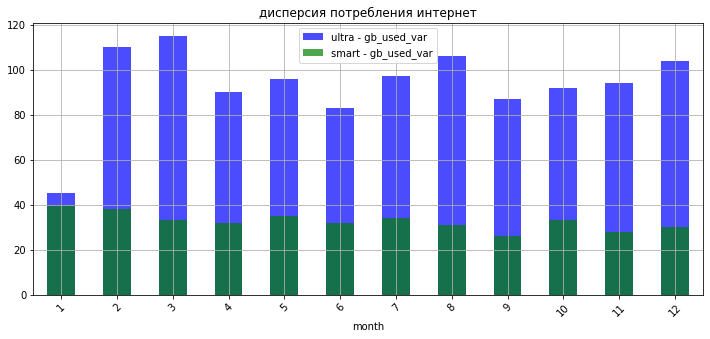

In [84]:
ax = df_gr_month_ultra.plot.bar(x='month', y = 'gb_used_var', color = 'Blue', label='ultra - gb_used_var', alpha=0.7,figsize=(12, 5),  title='дисперсия потребления интернет')
df_gr_month_smart.plot.bar(x='month', y = 'gb_used_var', color = 'Green', label='smart - gb_used_var',rot=45,alpha=0.7, grid = True, ax=ax);

- Диспресия по ультра в среднем 90 , по смарт - 35. Это означает что в тарифе смарт значения показателя объём интернет трафика менее рассеяны чем в ультре.

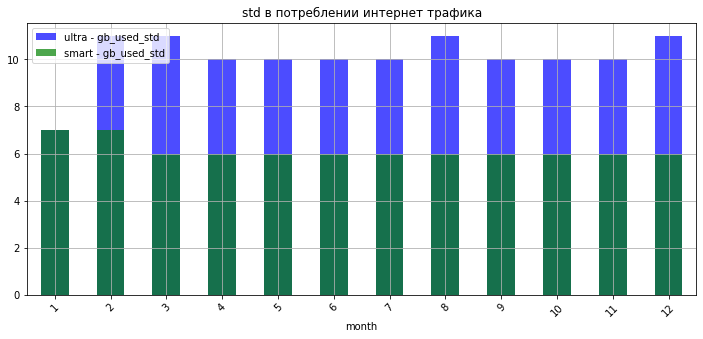

In [86]:
ax = df_gr_month_ultra.plot.bar(x='month', y = 'gb_used_std', color = 'Blue', label='ultra - gb_used_std', alpha=0.7,figsize=(12, 5),  title='std в потреблении интернет трафика')
df_gr_month_smart.plot.bar(x='month', y = 'gb_used_std', color = 'Green', label='smart - gb_used_std',rot=45,alpha=0.7, grid = True, ax=ax);

- стандартное отклонение в тарифе ультра - 10 , в тарифе смарт - 6. Это означает , что значения объем трафика в тарифе смарт ближе к среднему , чем в тарифе ультра.

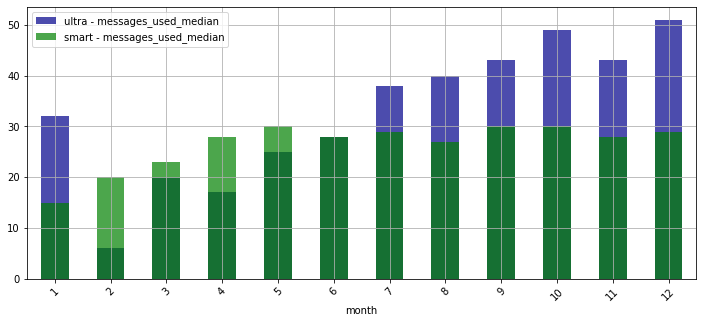

In [53]:
ax = df_gr_month_ultra.plot.bar(x='month', y = 'messages_used_median', color = 'DarkBlue', label='ultra - messages_used_median',alpha=0.7, figsize=(12, 5))
df_gr_month_smart.plot.bar(x='month', y = 'messages_used_median', color = 'Green', label='smart - messages_used_median',rot=45, grid = True,alpha=0.7, ax=ax);

- по использованию сообщений - какая-то аномалия, с февраля по июнь средние показатели по потреблению сообщений ушли вниз и по тарифу смарт и по ультра. Возможно это связано с тем , что значения не довыгрузились или выгрузились с ошибкой по данному периоду.
- посмотрев на остальные периоды можно селать вывод, что тратят в среднем абоненты ульра 40 - 45 сообщений в месяц, смарт - около 30

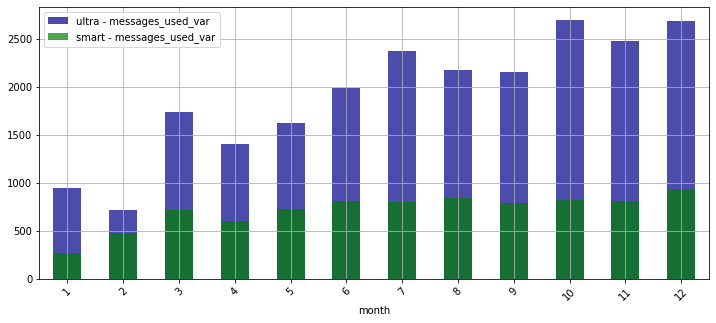

In [54]:
ax = df_gr_month_ultra.plot.bar(x='month', y = 'messages_used_var', color = 'DarkBlue', label='ultra - messages_used_var',alpha=0.7, figsize=(12, 5))
df_gr_month_smart.plot.bar(x='month', y = 'messages_used_var', color = 'Green', label='smart - messages_used_var',rot=45, grid = True,alpha=0.7, ax=ax);

- также видим большое рассеяние значений потребления сообщений в тарифе ультра и меньшее рассеяние в тарифе смарт. это хорошо будет видно на гистограммах далее.

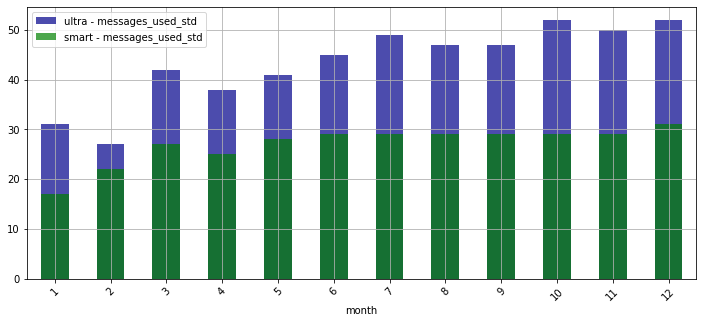

In [55]:
ax = df_gr_month_ultra.plot.bar(x='month', y = 'messages_used_std', color = 'DarkBlue', label='ultra - messages_used_std',alpha=0.7, figsize=(12, 5))
df_gr_month_smart.plot.bar(x='month', y = 'messages_used_std', color = 'Green', label='smart - messages_used_std',rot=45, grid = True,alpha=0.7, ax=ax);

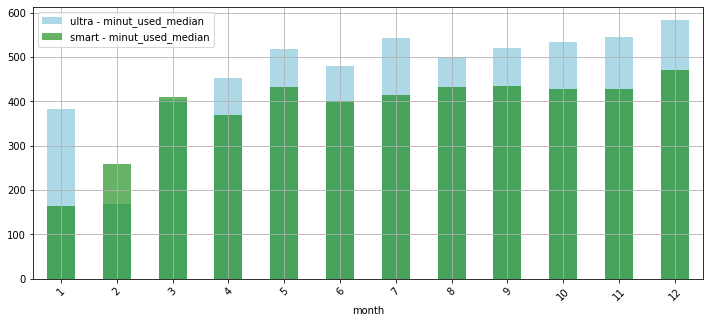

In [56]:
ax = df_gr_month_ultra.plot.bar(x='month', y = 'minut_used_median', color = 'LightBlue', label='ultra - minut_used_median', figsize=(12, 5))
df_gr_month_smart.plot.bar(x='month', y = 'minut_used_median', color = 'Green', label='smart - minut_used_median',rot=45, grid = True,alpha=0.6, ax=ax);

- в среднем 400 минут тратят абоненты смарт, 520 минут - абоненты ультра.

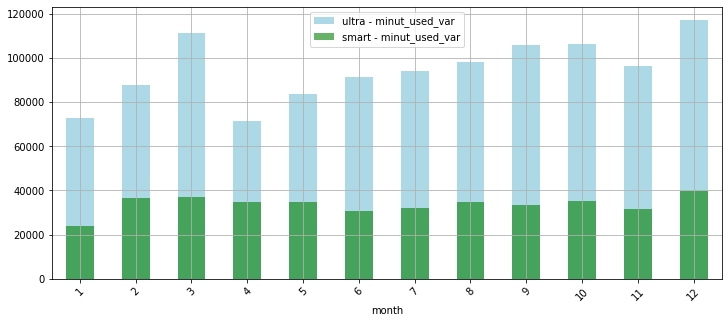

In [57]:
ax = df_gr_month_ultra.plot.bar(x='month', y = 'minut_used_var', color = 'LightBlue', label='ultra - minut_used_var', figsize=(12, 5))
df_gr_month_smart.plot.bar(x='month', y = 'minut_used_var', color = 'Green', label='smart - minut_used_var',rot=45, grid = True,alpha=0.6, ax=ax);

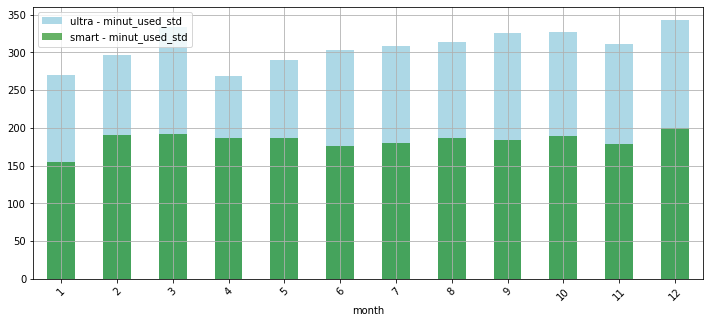

In [58]:
ax = df_gr_month_ultra.plot.bar(x='month', y = 'minut_used_std', color = 'LightBlue', label='ultra - minut_used_std', figsize=(12, 5))
df_gr_month_smart.plot.bar(x='month', y = 'minut_used_std', color = 'Green', label='smart - minut_used_std',rot=45, grid = True,alpha=0.6, ax=ax);

**теперь сгруппирую df по пользователям и возьму средние значения показателей по каждому пользователю и построю по ним распределения.**

In [59]:
df_gr_users = df.groupby(['tariff', 'user_id']).agg({
            'gb_used': ['median', 'mean',np.var,np.std], 
            'messages_used': ['median', 'mean',np.var,np.std], 
            'minut_used': ['median', 'mean',np.var,np.std]
            }).apply(np.ceil).reset_index()

df_gr_users.columns = ['_'.join(col).rstrip('_') for col in df_gr_users.columns.values]
#df_gr_users.rename(columns = {'gb_used_count' : 'count_users'}, inplace = True)
df_gr_users.round(2)

,tariff,user_id,gb_used_median,gb_used_mean,gb_used_var,gb_used_std,messages_used_median,messages_used_mean,messages_used_var,messages_used_std,minut_used_median,minut_used_mean,minut_used_var,minut_used_std
0,smart,1001,16.0,16.0,8.0,3.0,0.0,0.0,0.0,0.0,422.0,422.0,128.0,12.0
1,smart,1002,18.0,17.0,10.0,4.0,11.0,10.0,21.0,5.0,214.0,217.0,2730.0,53.0
2,smart,1005,8.0,9.0,6.0,3.0,49.0,46.0,208.0,15.0,594.0,551.0,26634.0,164.0
3,smart,1006,16.0,16.0,27.0,6.0,0.0,0.0,0.0,0.0,356.0,319.0,11981.0,110.0
4,smart,1007,15.0,15.0,14.0,4.0,26.0,25.0,63.0,8.0,480.0,487.0,17199.0,132.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
493,ultra,1476,16.0,17.0,54.0,8.0,5.0,5.0,9.0,3.0,492.0,468.0,33924.0,185.0
494,ultra,1485,23.0,23.0,NaN,NaN,155.0,155.0,NaN,NaN,584.0,584.0,NaN,NaN
495,ultra,1491,18.0,18.0,40.0,7.0,52.0,48.0,240.0,16.0,531.0,514.0,24317.0,156.0
496,ultra,1493,27.0,27.0,450.0,22.0,47.0,47.0,1922.0,44.0,372.0,372.0,79202.0,282.0


In [60]:
df_gr_users_ultra = df_gr_users.query('tariff == ("ultra")')
df_gr_users_smart = df_gr_users.query('tariff == ("smart")')


**Построим распределения пользователей по среднемесячным потреблениям минут разговоров; средним потреблениям интернет трафика; средним количеством отправленных сообщений в зависимости от тарифа**

Text(0.5, 0.98, 'гистограмма среднемесячного потребления минут')

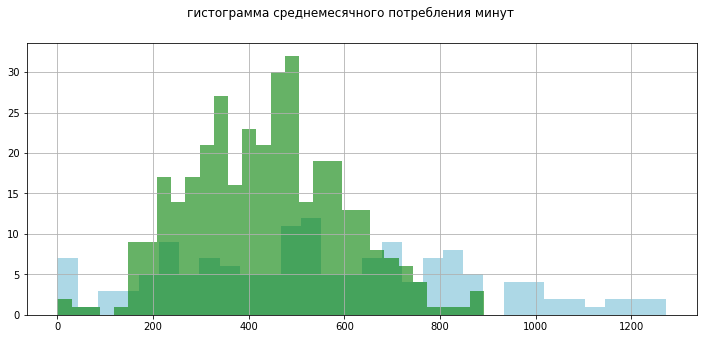

In [91]:
ax = df_gr_users_ultra['minut_used_median'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra', ) 
df_gr_users_smart['minut_used_median'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("гистограмма среднемесячного потребления минут")

- распределение по смарт тарифу показывает что большинство абонентов тратят от 150 до 700 минут, по ультра - данные сильнее разбросаны, но примерно от 200 до 1000 минут.

Text(0.5, 0.98, 'гистограмма дисперсии потребления минут')

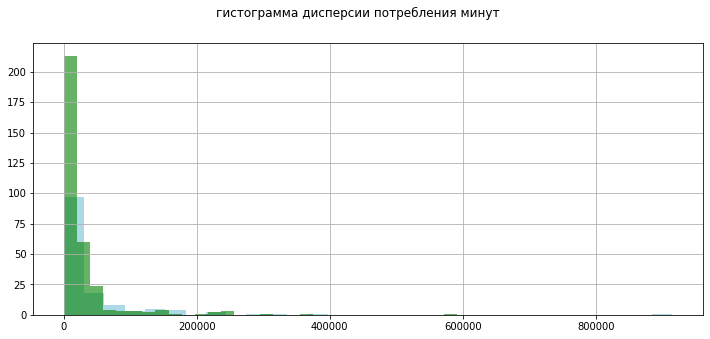

In [92]:
ax = df_gr_users_ultra['minut_used_var'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df_gr_users_smart['minut_used_var'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("гистограмма дисперсии потребления минут")

видно , что в потреблении минут дисперсии разных тарифов очень похожи.

Text(0.5, 0.98, 'std потребления минут')

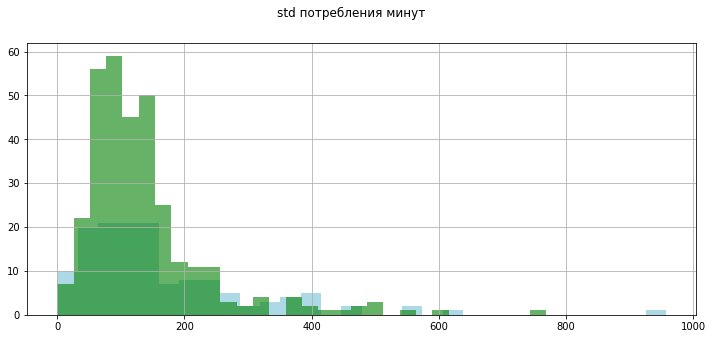

In [93]:
ax = df_gr_users_ultra['minut_used_std'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df_gr_users_smart['minut_used_std'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("std потребления минут")

соответственно и стандартное отклонение от среднего также имеет похожий вид. Видно , что большинство абонентов смарт тарифа расположено в зоне от 0 до 200 минут, в то время ка абоненты ультры распределены дальше вправо по оси х. 

среднее Std ультра больше чем среднее std смарт.

Text(0.5, 0.98, 'среднемесячное потребление gb')

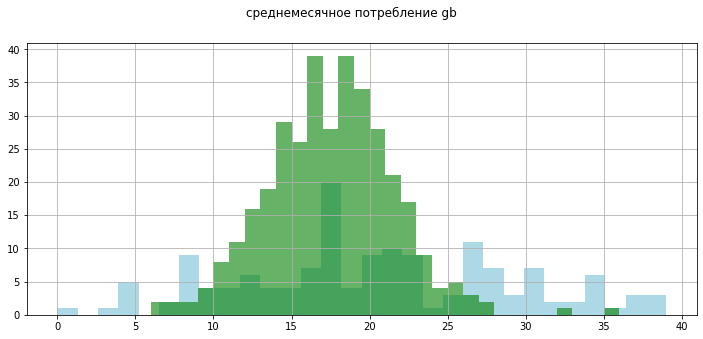

In [94]:
ax = df_gr_users_ultra['gb_used_median'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df_gr_users_smart['gb_used_median'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("среднемесячное потребление gb")

на этом графике видно, что абоненты смарта распределены ближе к воображаемой оси их среднего, в то время как абоненты ультра удалены от своего воображаемого среднего дальше.

Text(0.5, 0.98, 'gb_used_var')

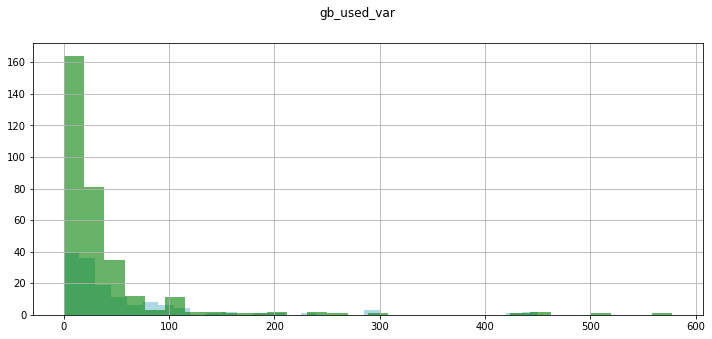

In [98]:
ax = df_gr_users_ultra['gb_used_var'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df_gr_users_smart['gb_used_var'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("gb_used_var")

дисперсия обоих тарифов имеет схожий характер

Text(0.5, 0.98, 'gb_used_std')

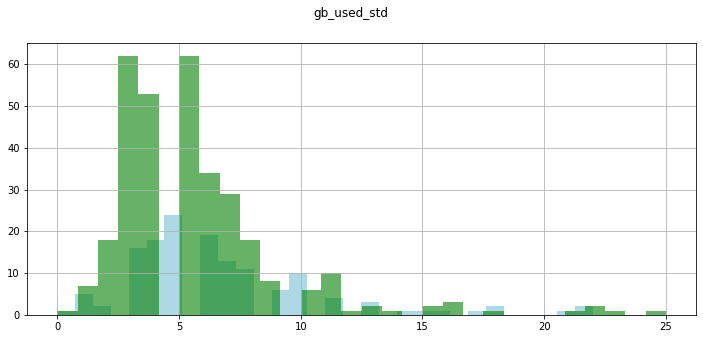

In [97]:
ax = df_gr_users_ultra['gb_used_std'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df_gr_users_smart['gb_used_std'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("gb_used_std")

стандартные отклонения по gb_used также имеют схожий характер у двух тарифов.

Text(0.5, 0.98, 'messages_used_median')

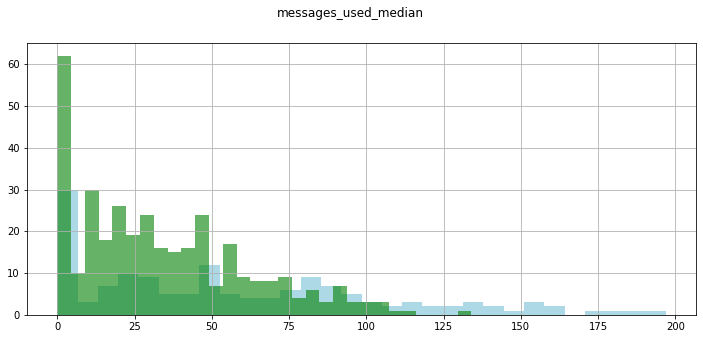

In [100]:
ax = df_gr_users_ultra['messages_used_median'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df_gr_users_smart['messages_used_median'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("messages_used_median")

Из распределения видно, что пользоваели ультры в среднем тратят больше сообщений.

Text(0.5, 0.98, 'messages_used_var')

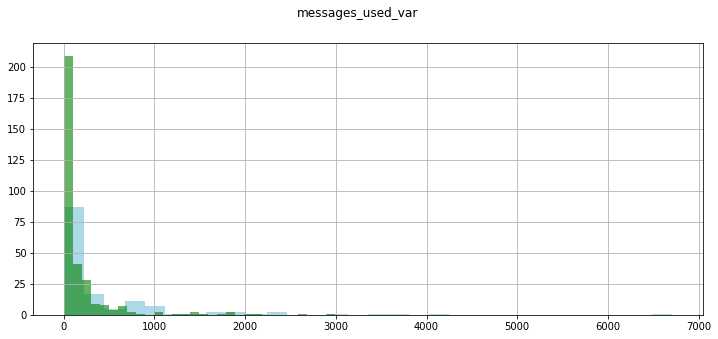

In [101]:
ax = df_gr_users_ultra['messages_used_var'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df_gr_users_smart['messages_used_var'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax)

pl.suptitle("messages_used_var")

видно, что дисперсия messages_used по ультра тарифу в среднем больше.

Text(0.5, 0.98, 'messages_used_std')

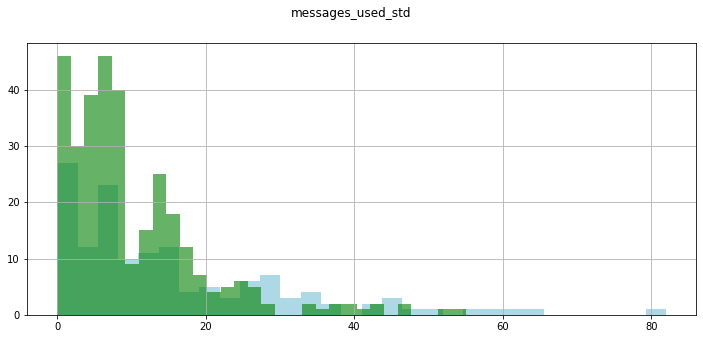

In [102]:
ax = df_gr_users_ultra['messages_used_std'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df_gr_users_smart['messages_used_std'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("messages_used_std")

messages_used_std по абонентам ультра также в среднем больше.

<div class="alert alert-warning" style="border-radius: 15px; box-shadow: 4px 4px 4px; border: 1px solid ">
<b> Комментарий ревьюера</b>
    
Кроме того, без комментариев графики будут не понятны клиенту. Нужно не только подписывать их, но и комментировать. </div>

<div class="alert alert-info">
<b>добавил комментарии и заголовки</b>
<br>
</div>

**Строю боксплоты по df**

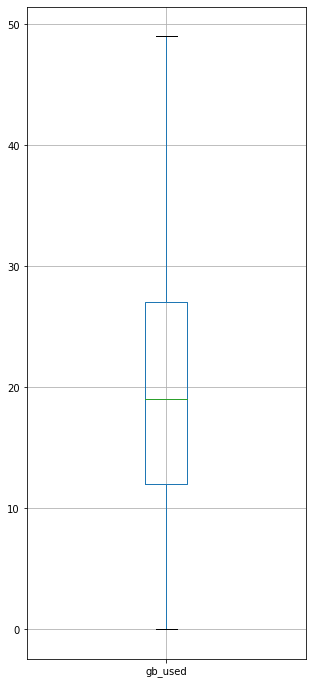

In [70]:
df[df['tariff']=='ultra'].boxplot('gb_used', figsize=(5,12))

**почти всезначения лежат в диапазоне от 0 до 49, первый квартиль - 12, второй(он же медиана) - 19, третий - 27 Гб. Около 80 % абонентов тарифа ультра не превышают установленный лимит по ГБ, на остальных 20 % - оператор зарабатывает сверх абонентской платы.**

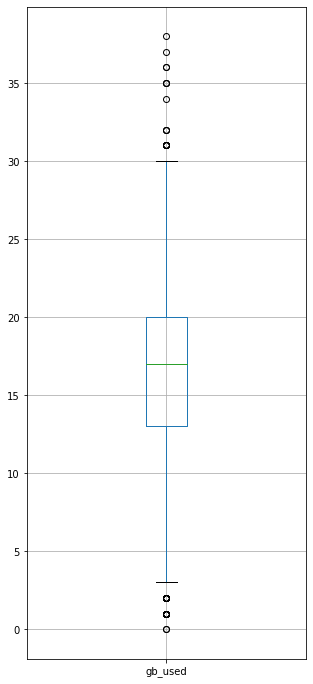

In [71]:
df[df['tariff']=='smart'].boxplot('gb_used', figsize=(5,12))

**среднее - 17, межквартильный размах 13 - 20, диапазон почти всех значений 3 - 30.
меньше 50 % абонентов смарт не превышают установленный лимит 15 Гб, на остальных абонентах (> 50 %) оператор зарабатывает сверх абонентской платы. Соответственно им нужно предложить перейти на тариф Ультра.**

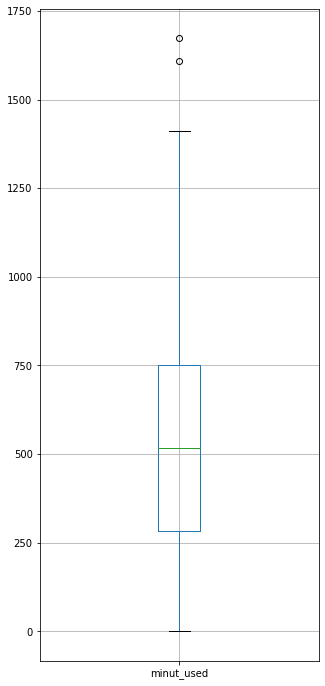

In [72]:
df[df['tariff']=='ultra'].boxplot('minut_used', figsize=(5,12))

**Границы почти всех значений 0 - 1400, медиана - 520 примерно.
По тарифу ультра установленного лимита не выговаривает никто. Есть смысл пересмотреть лимиты минут по данному тарифу, возможно стоит их уменьшить к примеру до 1500 , слегка понизив абонентскую плату или добавив количество сообщений или засчет добавления допопций - например бесплатный трафик какой-то соц сети и т.д.**

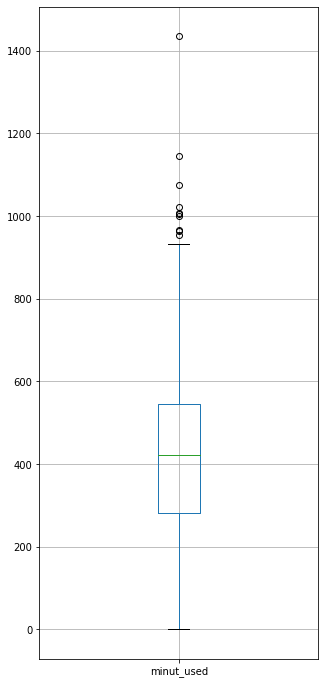

In [73]:
df[df['tariff']=='smart'].boxplot('minut_used', figsize=(5,12))

**по смарт тарифу - границы почти всех значений 0 - 950, медиана - 420 примерно. при лимите 500 минут, примерно 60 % не выходят за рамки лимита, на остальных 40 % оператор зарабатывает сверх.
Для оптимизации процессов  -  нужно предложить данным пользователям перейти на тариф Ультра.**

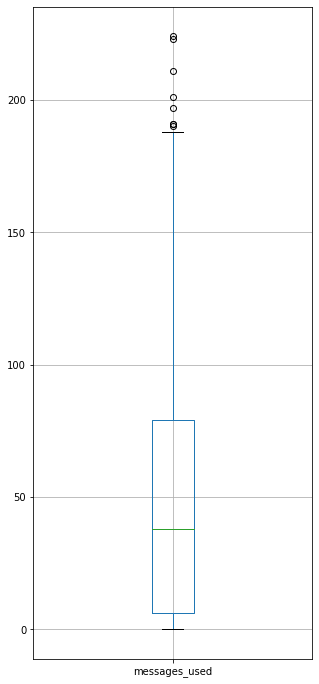

In [74]:
df[df['tariff']=='ultra'].boxplot('messages_used', figsize=(5,12))

**в среднем расход 40 . На графике видно что никто из абонентов Ультры не тратит больше 300 сообщений из уст. лимита 1000 . Поэтому считаю , что нужно пересмотреть данный лимит уменьшив его к примеру до 500 . За место этого предложить пользователям дополнительные гигабайты или пакеты гигабайт по сниженной цене.**

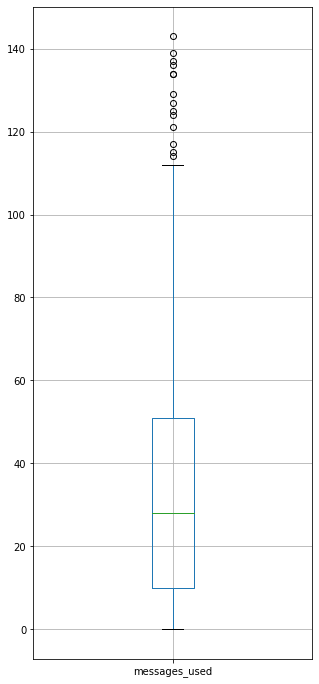

In [75]:
df[df['tariff']=='smart'].boxplot('messages_used', figsize=(5,12))

**Видно что абоненты смарт тарифа примерно 25 % из них превышают лимит по сообщениям, на них оператор зарабатывает сверх. Можно придумать какие -то дополнительные пакеты по сообщениям и предлагать их данным пользователям.**

**Строю распределения по df**

Text(0.5, 0.98, 'Гистограмма minut_used')

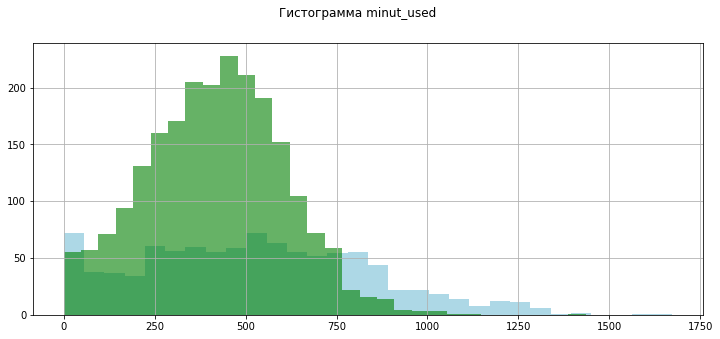

In [103]:
ax = df[df['tariff']=='ultra']['minut_used'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df[df['tariff']=='smart']['minut_used'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("Гистограмма minut_used")

зелёным показано распределение по смарт тарифу, синим - по ультра.

по графику чётко видно , что среднее по смарту примерно 400 минут, по ультре - около 600 .

Text(0.5, 0.98, 'Гистограмма gb_used')

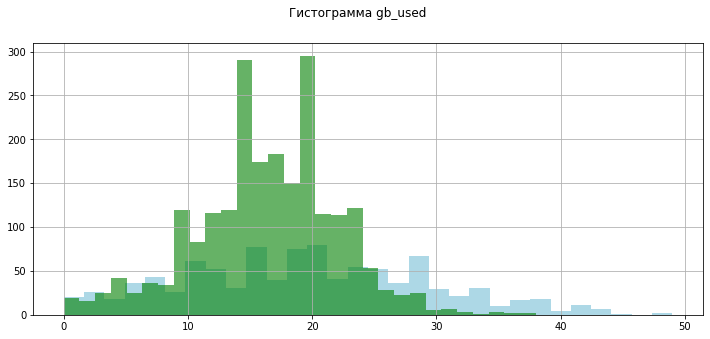

In [104]:
ax = df[df['tariff']=='ultra']['gb_used'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df[df['tariff']=='smart']['gb_used'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("Гистограмма gb_used")

видно что график распределения ультры как бы смещён вправо относительно распределения смарта, соответственно центр распределения ультры будет правее центра распределения смарта. Также видно, что график ультра более пологий, это означает что std ультра больше, чем std смарта.

Text(0.5, 0.98, 'Гистограмма messages_used')

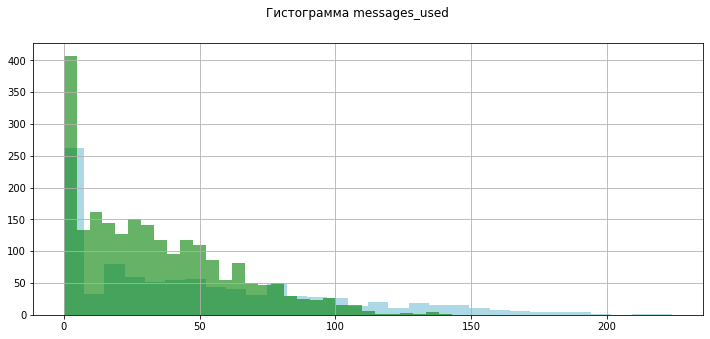

In [105]:
ax = df[df['tariff']=='ultra']['messages_used'].hist(bins=30, figsize=(12,5),color = 'LightBlue', label='ultra') 
df[df['tariff']=='smart']['messages_used'].hist(bins=30, figsize=(12,5),color = 'Green',alpha=0.6, label='smart', ax=ax) 

pl.suptitle("Гистограмма messages_used")

центр распределения по абонентам ультры правее центра распределений по смарт тарифу. Соответственно среднее потребление сообщений в ультра выше, чем в тарифе смарт.

## проверка гипотез

### нам нужно проверить , что средняя выручка отличается в зависимости от тарифа.

для этого формулируем гипотезу Н0, что выручки по тарифам равны.
Критический уровень значимости задаём - 2 %.
Соответственно если нулевая гипотеза будет отвергнута, то гипотеза что выручка отличается - не сможет быть отвергнута.

In [79]:
sample_1 = df[df['tariff']=='ultra'][['total_price']]
sample_2 = df[df['tariff']=='smart'][['total_price']]

alpha = .02 # критический уровень статистической значимости
# если p-value окажется меньше него - отвегнем гипотезу

results = st.ttest_ind(
    sample_1, 
    sample_2)

print('p-значение: ', results.pvalue)

if results.pvalue < alpha:
    print("Отвергаем нулевую гипотезу")
else:
    print("Не получилось отвергнуть нулевую гипотезу") 

p-значение:  [1.42298144e-160]
Отвергаем нулевую гипотезу


**Гипотеза - что средние выручки по разным тарифам различаются не может быть отвергенута, то есть мы её как бы подтверждаем.**

<div class="alert alert-success" style="border-radius: 15px; box-shadow: 4px 4px 4px; border: 1px solid ">
<b> Комментарий ревьюера</b>
    
Ну да. Средняя месячная выручка бюджетного тарифа не дотягивает даже до абонентской платы дорогого тарифа.
</div>

### рассмотрим следующую гипотезу. средняя выручка пользователей из Москвы отличается от выручки пользователей из других регионов.

для проверки данной гипотезы  , выдвинем гипотезу Н0 , что выручки с московских и региональных абонентов равны.

In [80]:
sample_1 = df[df['city']=='Москва'][['total_price']]
sample_2 = df[df['city']!='Москва'][['total_price']]

alpha = .02 # критический уровень статистической значимости
# если p-value окажется меньше него - отвегнем гипотезу

results = st.ttest_ind(
    sample_1, 
    sample_2)

print('p-значение: ', results.pvalue)

if results.pvalue < alpha:
    print("Отвергаем нулевую гипотезу")
else:
    print("Не получилось отвергнуть нулевую гипотезу") 

p-значение:  [0.54401529]
Не получилось отвергнуть нулевую гипотезу


**вероятность, что нулевая гипотеза верна - 54 %, следовательно гипотезу - средняя выручка пользователей из Москвы отличается от выручки пользователей из других регионов - мы отвергаем.**

## Общий вывод

- с каждым месяцем количество абонентов пропорционально возрастает, причём количество пользователей тарифа смарт растет быстрее. пользователей смарт-тарифа больше чем в 2 раза превышает количество абонентов ультра почти в каждом месяце.

- В тарифе ультра в среднем каждый абонент тратит 19 Гб интернет-трафика , в смарт - 16 - 17 Гб, причем в январе и феврале наблюдается просадка в потреблении трафика.

- Диспресия по ультра в среднем 90 , по смарт - 35. Это означает что в тарифе смарт значения показателя объём интернет трафика менее рассеяны чеем в ультре.

- стандартное отклонение в тарифе ультра - 10 , в тарифе смарт - 6. Это означает , что значения объем трафика в тарифе смарт ближе к среднему , чем в тарифе ультра.

- по использованию сообщений - какая-то аномалия, с февраля по июнь средние показатели по потреблению сообщений ушли вниз и по тарифу смарт и по ультра. Возможно это связано с тем , что значения не довыгрузились или выгрузились с ошибкой по данному периоду.
- посмотрев на остальные периоды можно селать вывод, что тратят в среднем абоненты ульра 40 - 45 сообщений в месяц, смарт - около 30

- в среднем 400 минут тратят абоненты смарт, 520 минут - абоненты ультра.

- почти всезначения лежат в диапазоне от 0 до 49, первый квартиль - 12, второй(он же медиана) - 19, третий - 27 Гб. Около 80 % абонентов тарифа ультра не превышают установленный лимит по ГБ, на остальных 20 % - оператор зарабатывает сверх абонентской платы.

- тариф смарт. среднее - 17, межквартильный размах 13 - 20, диапазон почти всех значений 3 - 30. меньше 50 % абонентов смарт не превышают установленный лимит 15 Гб, на остальных абонентах (> 50 %) оператор зарабатывает сверх абонентской платы. Соответственно им нужно предложить перейти на тариф Ультра.

- Границы почти всех значений 0 - 1400, медиана - 520 примерно. По тарифу ультра установленного лимита не выговаривает никто. Есть смысл пересмотреть лимиты минут по данному тарифу, возможно стоит их уменьшить к примеру до 1500 , слегка понизив абонентскую плату или добавив количество сообщений или засчет добавления допопций - например бесплатный трафик какой-то соц сети и т.д.**

- по смарт тарифу - границы почти всех значений 0 - 950, медиана - 420 примерно. при лимите 500 минут, примерно 60 % не выходят за рамки лимита, на остальных 40 % оператор зарабатывает сверх. Для оптимизации процессов  -  нужно предложить данным пользователям перейти на тариф Ультра.

- в среднем расход 40 . На графике видно что никто из абонентов Ультры не тратит больше 300 сообщений из уст. лимита 1000 . Поэтому считаю , что нужно пересмотреть данный лимит уменьшив его к примеру до 500 . За место этого предложить пользователям дополнительные гигабайты или пакеты гигабайт по сниженной цене.

- Видно что абоненты смарт тарифа примерно 25 % из них превышают лимит по сообщениям, на них оператор зарабатывает сверх. Можно придумать какие -то дополнительные пакеты по сообщениям и предлагать их данным пользователям.


**в итоге, если кратко:**
1. выручка по тарифу ультра выше чем по тарифу смарт. Следовательно - нужно снижать цену абонентской платы на ультра,и активно предлагать перейти со смарта на ультру абонентам кто превышает установленные тарифом лимиты.
2. при этом необходимо пересмотреть установленные тарифом ультра лимиты, ограничив кол-во сообщений до 500 шт, минут - до 1500.
3. добавить допопций - пакеты сообщений, пакеты гигабайт по сниженной цене, бесплатный трафик на соц сети - что повысит лояльность абонентов и привлекательность для потенциальных.
4. выручка по регионам почти не отличается от выручки по Москве.


<div class="alert alert-success" style="border-radius: 15px; box-shadow: 4px 4px 4px; border: 1px solid ">
<b> Комментарий ревьюера</b>
    
Согласна. </div>